In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from getdist.mcsamples import loadMCSamples

In [1]:


# 1. LOAD CHAINS
chains = loadMCSamples("../chains_mavan_desy5/pngb_mavan_desy5")

# 2. SETTINGS
nsamples = 200   # Start small to test if it works, then increase to 200+
z_grid = np.linspace(0, 10, 200)
all_meff = []

# Use weights for statistical correctness
weights = chains.weights
indices = np.random.choice(len(weights), size=nsamples,replace=False, p=weights/weights.sum())

print(f"Starting reconstruction for {nsamples} samples...")

# 3. LOOP
for k, idx in enumerate(indices):
    cosmo = Class()
    try:
        # Extract parameters
        p = lambda name: chains.samples[idx, chains.index[name]]
        
        params = {
            'omega_b': p('omega_b'),
            'omega_cdm': p('omega_cdm'),
            'H0': p('H0'),
            'A_s': p('A_s'),
            'n_s': p('n_s'),
            'N_ur': 2.0308,
            'N_ncdm': 1,
            'm_ncdm': 0.06,
            'T_ncdm': 0.71611,
            'deg_ncdm': 1,
            'beta_ncdm': p('beta_ncdm'),
            'scf_parameters': f"{p('f_pngb')}, -7, 0.4, 0.0",
            'Omega_fld': 0.0,
            'Omega_scf': -1,
            'Omega_Lambda': 0.0,
            'mavan_ncdm': 'True',
            'gauge': 'synchronous',
            'ncdm_fluid_approximation': 2,
            'non_linear': 'halofit',
            'nonlinear_min_k_max': 5,          
            'attractor_ic_scf': 'no',
            'scf_tuning_index': 1,
            'output': 'mPk',
            'P_k_max_1/Mpc': 1.0,
        }

        cosmo.set(params)
        cosmo.compute()

        bg = cosmo.get_background()
        
         # =========================
        # Background quantities
        # =========================
        z_bg = bg['z']
        phi_scf = bg['phi_scf']
        
        # sort in ascending z
        order = np.argsort(z_bg)
        
        z_sorted = z_bg[order]
        phi_sorted = phi_scf[order]
        
        beta_val = p('beta_ncdm')
        
        # present-day neutrino mass
        m0 = 0.06
        
        # phi today
        phi0 = phi_sorted[0]
        
        # effective neutrino mass
        m_eff = m0 * np.exp(
            beta_val * (phi_sorted - phi0)
        )
        
        # interpolate
        m_interp = np.interp(
            z_grid,
            z_sorted,
            m_eff
        )
        
        all_meff.append(m_interp)
        print(f"Success: {k+1}/{nsamples}", end="\r")

    except Exception as e:
        print(f"\nError at index {idx}: {e}")
    finally:
        cosmo.struct_cleanup()
        cosmo.empty()

# 4. STATISTICS & PLOTTING
if len(all_meff) == 0:
    print("Error: No successful CLASS runs. Check your parameter names and CLASS version.")
else:
    all_meff = np.array(all_meff)
    
    median = np.percentile(all_meff, 50, axis=0)
    low68, high68 = np.percentile(all_meff, [16, 84], axis=0)
    low95, high95 = np.percentile(all_meff, [2.5, 97.5], axis=0)


Starting reconstruction for 200 samples...


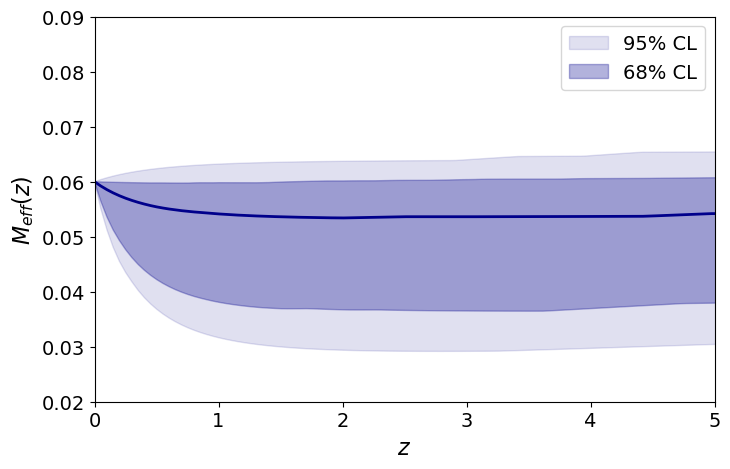

In [3]:
plt.figure(figsize=(8, 5))



plt.fill_between(
    z_grid,
    low95,
    high95,
    alpha=0.12,
    color='darkblue',
    label='95% CL'
)
plt.fill_between(
    z_grid,
    low68,
    high68,
    alpha=0.30,
    color='darkblue',
    label='68% CL'
)

plt.plot(
    z_grid,
    median,
    color='darkblue',
    lw=2,
)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel('$z$', fontsize=16)
plt.ylabel('$M_{eff}(z)$', fontsize=16)
plt.xlim(0, 5)
plt.ylim(0.02, 0.09)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=14)
plt.savefig('meff_data.pdf', bbox_inches='tight')
plt.show()

In [6]:
# 1. LOAD CHAINS
samples = loadMCSamples("../chains_mavan_desy5/pngb_mavan_desy5")
stats = samples.getMargeStats()
beta = stats.parWithName("beta_ncdm")

print("Loaded prior:",
      samples.ranges.getLower("beta_ncdm"),
      samples.ranges.getUpper("beta_ncdm"), stats)

for level, limit in zip(stats.limits, beta.limits):
    print(f"{100*level:g}%:", limit.limitType(),
          limit.lower, limit.upper)

Loaded prior: -1.0 6.0 Marginalized limits: 0.68; 0.95; 0.99

parameter                                 mean           sddev          lower1         upper1         limit1 lower2         upper2         limit2 lower3         upper3         limit3 
logA                                      3.0471272E+00  1.3964599E-02  3.0326128E+00  3.0600291E+00  two    3.0210586E+00  3.0761237E+00  two    3.0124264E+00  3.0848402E+00  two     logA
n_s                                       9.6783608E-01  3.4336002E-03  9.6446230E-01  9.7119103E-01  two    9.6092409E-01  9.7449038E-01  two    9.5874801E-01  9.7677669E-01  two     n_s
H0                                        6.7666530E+01  4.8592762E-01  6.7312561E+01  6.8241773E+01  two    6.6640913E+01  6.8513493E+01  two    6.6261171E+01  6.8644545E+01  two     H0
omega_b                                   2.2313055E-02  1.2558986E-04  2.2186846E-02  2.2439791E-02  two    2.2065606E-02  2.2550524E-02  two    2.1987384E-02  2.2622330E-02  two     omega_

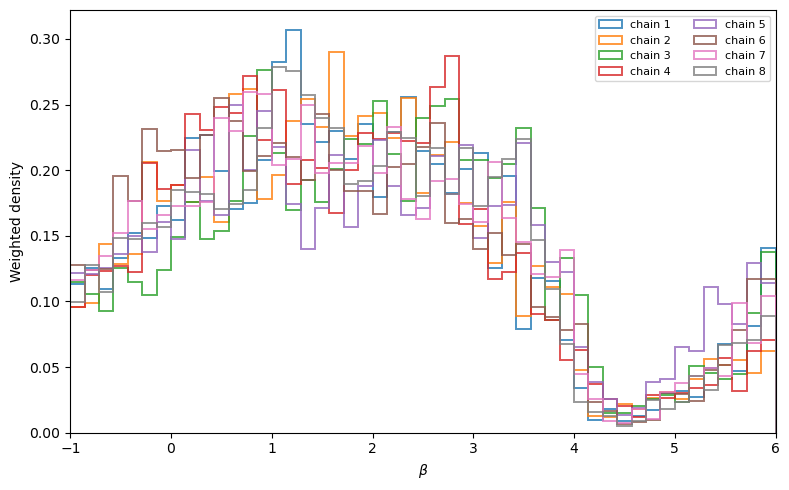

In [9]:
bins = np.linspace(-1, 6, 50)
beta_index = samples.index["beta_ncdm"]

plt.figure(figsize=(8, 5))

for i, chain in enumerate(samples.getSeparateChains(), start=1):
    beta_values = chain.samples[:, beta_index]

    plt.hist(
        beta_values,
        bins=bins,
        weights=chain.weights,
        density=True,
        histtype="step",
        linewidth=1.4,
        alpha=0.8,
        label=f"chain {i}",
    )

plt.xlabel(r"$\beta$")
plt.ylabel("Weighted density")
plt.xlim(-1, 6)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig('weighted_density_per_chains.png', bbox_inches='tight')
plt.show()

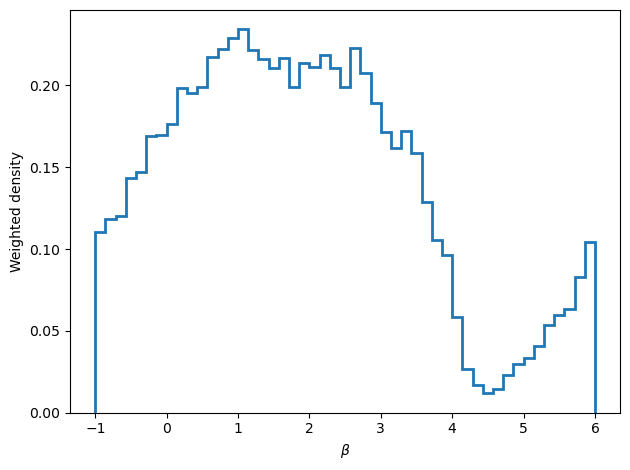

In [10]:
beta_values = samples.getParams().beta_ncdm

plt.hist(
    beta_values,
    bins=bins,
    weights=samples.weights,
    density=True,
    histtype="step",
    linewidth=2,
)
plt.xlabel(r"$\beta$")
plt.ylabel("Weighted density")
plt.tight_layout()
plt.savefig('weighted_density.png', bbox_inches='tight')

plt.show()

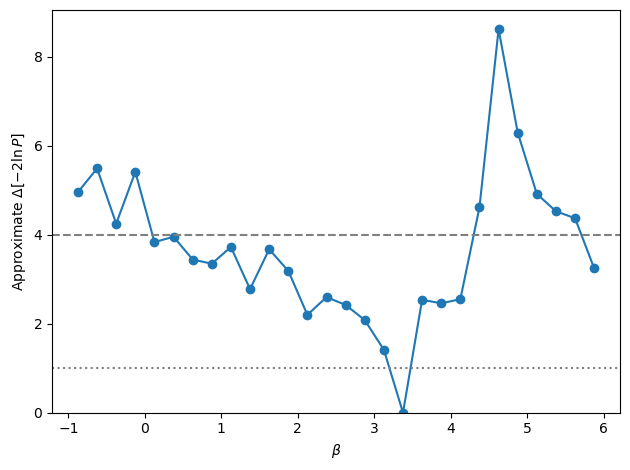

In [12]:
beta_values = samples.getParams().beta_ncdm
q = 2 * samples.loglikes  # -2 log posterior

edges = np.linspace(-1, 6, 29)
centers = 0.5 * (edges[:-1] + edges[1:])
q_profile = np.full(len(centers), np.nan)

for i in range(len(centers)):
    mask = (beta_values >= edges[i]) & (beta_values < edges[i + 1])
    if np.any(mask):
        q_profile[i] = np.min(q[mask])

q_profile -= np.nanmin(q_profile)

plt.plot(centers, q_profile, marker="o")
plt.axhline(1, color="gray", ls=":")
plt.axhline(4, color="gray", ls="--")
plt.xlabel(r"$\beta$")
plt.ylabel(r"Approximate $\Delta[-2\ln P]$")
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig('-2lnp.png', bbox_inches='tight')

plt.show()